In [1]:
import os
import certifi, requests
from dotenv import  load_dotenv

from langchain_openai import ChatOpenAI
from langchain.tools import  tool
from langchain_community.tools.tavily_search import  TavilySearchResults
import langchainhub as hub

/tmp/ipykernel_57264/2542647417.py:7: DeprecationWarning: `langchain-community` is being sunset and is no longer actively maintained. See https://github.com/langchain-ai/langchain-community/issues/674 for details and migration guidance toward standalone integration packages.
  from langchain_community.tools.tavily_search import  TavilySearchResults


In [2]:
from langchain_classic.agents import create_react_agent, AgentExecutor

In [3]:
# Load the env
os.environ['SSl_CERT_FILE'] = certifi.where()
load_dotenv()

OPEN_API_KEY = os.getenv("OPEN_API_KEY ")
TAVITY_API_KEY = os.getenv("TAVILY_API_KEY")
WEATHERSTACK_API_KEY = os.getenv("WEATHERSTACK_API_KEY")

In [4]:
search_tool = TavilySearchResults(max_results=2) 

/tmp/ipykernel_57264/675728694.py:1: LangChainDeprecationWarning: The class `TavilySearchResults` was deprecated in LangChain 0.3.25 and will be removed in 1.0. An updated version of the class exists in the `langchain-tavily package and should be used instead. To use it run `pip install -U `langchain-tavily` and import as `from `langchain_tavily import TavilySearch``.
  search_tool = TavilySearchResults(max_results=2)


In [5]:
# custom tool
from langchain.tools import tool
import requests

In [20]:
@tool
def get_weather_data(city: str) -> str:
    """
    Fetch current weather information for a city using WeatherStack API.
    """

    url = "https://api.weatherstack.com/current?access_key={WEATHERSTACK_API_KEY}&query={city}"

    params = {
        "access_key": WEATHERSTACK_API_KEY,
        "query": city
    }

    try:
        response = requests.get(
            url=url,
        )

        response.raise_for_status()
        data = response.json()

        if "current" not in data:
            return f"Could not fetch weather data for {city}: {data.get('error', {}).get('info', 'Unknown error')}"

        current = data["current"]
        location = data["location"]

        return (
            f"City: {location['name']}\n"
            f"Country: {location['country']}\n"
            f"Temperature: {current['temperature']}°C\n"
            f"Weather: {current['weather_descriptions'][0]}\n"
            f"Humidity: {current['humidity']}%\n"
            f"Wind Speed: {current['wind_speed']} km/h\n"
            f"Feels Like: {current['feelslike']}°C"
        )

    except requests.exceptions.RequestException as e:
        return f"Weather API request failed: {str(e)}"

    except (KeyError, IndexError, TypeError) as e:
        return f"Error processing weather data: {str(e)}"

In [21]:
w_tool = get_weather_data.invoke("New Delhi")

print(w_tool)

Weather API request failed: 401 Client Error: Unauthorized for url: https://api.weatherstack.com/current?access_key=%7BWEATHERSTACK_API_KEY%7D&query=%7Bcity%7D


In [8]:
search_tool.invoke("what is the current langchain ecosystem")

[{'title': 'The LangChain Ecosystem Is Expanding At A Tremendous Pace',
  'url': 'https://cobusgreyling.substack.com/p/the-langchain-ecosystem-is-expanding',
  'content': 'LangChain is becoming to some degree the de facto standard for building LLM-based Generative Apps. LangChain is my first port of call for experimenting with Autonomous Agents & Tools and searching for code implementations of the newest prompt engineering research.\n\nFor a graphic IDE flow builder, Flowise and LangFlow are very compelling options.\n\nHere are a few highlights in terms of recent LangChain developments…\n\n# LangChain — What Changed?\n\n## LangChain, LangChain-Core & LangChain-Community\n\nAccording the LangChain, the existing LangChain package is being separated into three separate packages.\n\n## LangChain\n\nLangChain contains use-case specific chains, agents, and RAG code which acts as the backbone of cognitive applications.\n\n## LangChain-Core\n\nLangChain-Core contains: [...] ## LangChain-Core\n

In [9]:
# LLM
llm = ChatOpenAI(model ='gpt-4.1-mini',
                api_key = OPEN_API_KEY)

llm

ChatOpenAI(metadata={'lc_versions': {'langchain-core': '1.8.1', 'langchain': '1.4.3', 'langchain-openai': '1.8.0'}}, profile={'name': 'GPT-4.1 mini', 'release_date': '2025-04-14', 'last_updated': '2025-04-14', 'open_weights': False, 'max_input_tokens': 1047576, 'max_output_tokens': 32768, 'text_inputs': True, 'image_inputs': True, 'audio_inputs': False, 'pdf_inputs': True, 'video_inputs': False, 'text_outputs': True, 'image_outputs': False, 'audio_outputs': False, 'video_outputs': False, 'reasoning_output': False, 'tool_calling': True, 'structured_output': True, 'attachment': True, 'temperature': True, 'image_url_inputs': True, 'pdf_tool_message': True, 'image_tool_message': True, 'tool_choice': True, 'tool_call_streaming': True, 'mid_conversation_system_messages': True, 'mid_conversation_tools': False}, client=<openai.resources.chat.completions.completions.Completions object at 0x70b642b51550>, async_client=<openai.resources.chat.completions.completions.AsyncCompletions object at 0x70

In [10]:
response = llm.invoke("what year it yet")
response

AIMessage(content='Today is 2024. How can I assist you further?', additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 13, 'prompt_tokens': 11, 'total_tokens': 24, 'completion_tokens_details': {'accepted_prediction_tokens': 0, 'audio_tokens': 0, 'reasoning_tokens': 0, 'rejected_prediction_tokens': 0, 'text_tokens': None}, 'prompt_tokens_details': {'audio_tokens': 0, 'cache_write_tokens': None, 'cached_tokens': 0, 'image_tokens': None, 'text_tokens': None}}, 'model_provider': 'openai', 'model_name': 'gpt-4.1-mini-2025-04-14', 'system_fingerprint': 'fp_9c09c50726', 'id': 'chatcmpl-Ekiwec68i6O5bN93XlxfwMpW1Jmrj', 'service_tier': 'default', 'finish_reason': 'stop', 'logprobs': None}, id='lc_run--01a1e2b0-3e1f-7583-a150-9c158c06c210-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 11, 'output_tokens': 13, 'total_tokens': 24, 'input_token_details': {'audio': 0, 'cache_read': 0}, 'output_token_details': {'audio': 0, 'reasoning':

In [11]:
from langsmith import Client

client = Client()

prompt = client.pull_prompt(
    "hwchase17/react",
    dangerously_pull_public_prompt=True
)

print(prompt)

input_variables=['agent_scratchpad', 'input', 'tool_names', 'tools'] input_types={} partial_variables={} metadata={'lc_hub_owner': 'hwchase17', 'lc_hub_repo': 'react', 'lc_hub_commit_hash': 'd15fe3c426f1c4b3f37c9198853e4a86e20c425ca7f4752ec0c9b0e97ca7ea4d'} template='Answer the following questions as best you can. You have access to the following tools:\n\n{tools}\n\nUse the following format:\n\nQuestion: the input question you must answer\nThought: you should always think about what to do\nAction: the action to take, should be one of [{tool_names}]\nAction Input: the input to the action\nObservation: the result of the action\n... (this Thought/Action/Action Input/Observation can repeat N times)\nThought: I now know the final answer\nFinal Answer: the final answer to the original input question\n\nBegin!\n\nQuestion: {input}\nThought:{agent_scratchpad}'


In [12]:
tools = [search_tool,get_weather_data]

In [13]:
llm = llm.bind_tools(tools)

### ReAct
ReAct Agent and AgentExecutor work together to build AI agents that can think through a task, use tools, observe results, and produce a final answer

#### 1. What is a ReAct Agent?
ReAct stands for Reasoning + Acting.

It is an agent architecture in which an LLM follows a cycle:
1. Reasoning: Understands what the user is asking.
2. Action: Decides which tool to use.
3. Observation: Receives the result from the tool.
4. Reasoning again: Decides what to do next.
5. Final Answer: Responds to the user.


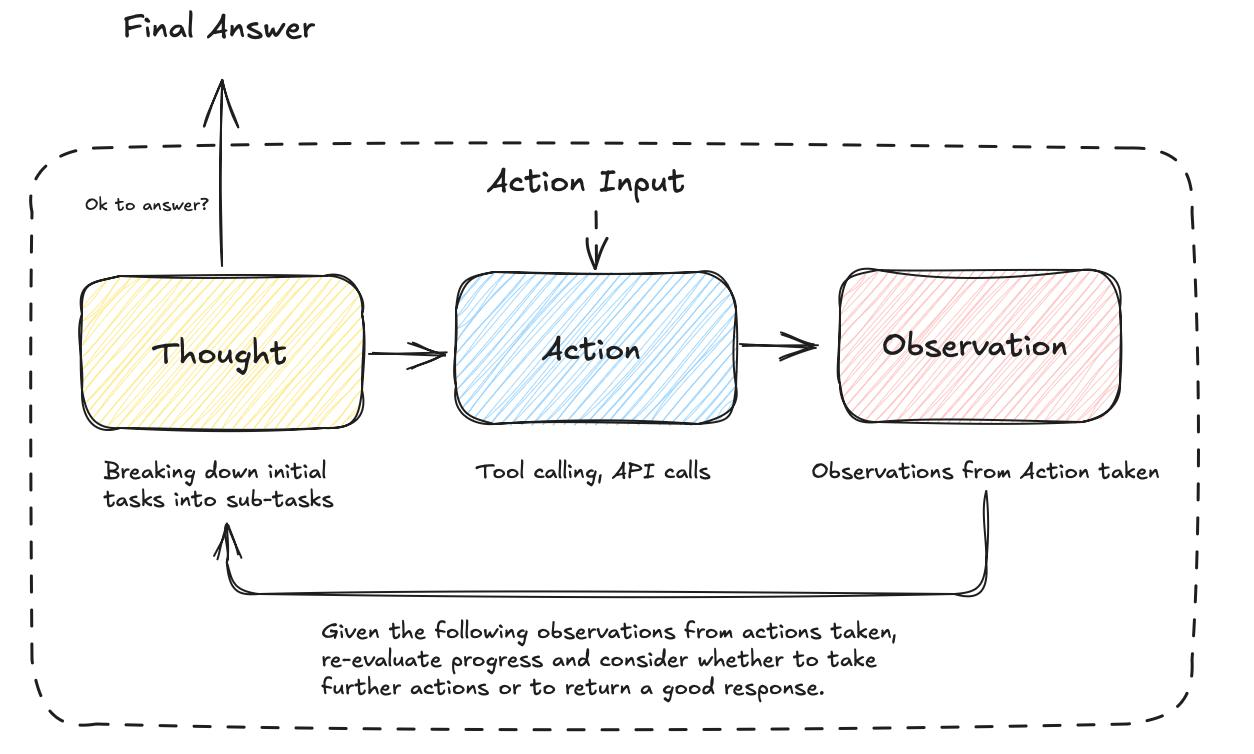

#### 2. What is AgentExecutor?
Think of AgentExecutor as the manager or controller of the agent.

The ReAct agent decides what action should be performed.

AgentExecutor actually manages the execution of those actions.

Its responsibilities include:
- Receiving the user's input.
- Sending the input to the agent.
- Reading the agent's action.
- Finding and executing the requested tool.
- Returning the tool's observation to the agent.
- Repeating the process until the agent produces a final answer.
- Managing execution limits and errors.

| ReAct Agent | AgentExecutor |
|---|---|
| Decides what to do | Executes the decisions |
| Uses the LLM | Manages the execution loop |
| Selects tools | Calls the selected tools |
| Processes observations | Sends observations back to the agent |
| Generates final answer | Returns final result |

In [14]:
# create agent

agent = create_react_agent(
    llm = llm,
    tools = tools,
    prompt =prompt
)
agent

RunnableAssign(mapper={
  agent_scratchpad: RunnableLambda(lambda x: format_log_to_str(x['intermediate_steps']))
})
| PromptTemplate(input_variables=['agent_scratchpad', 'input'], input_types={}, partial_variables={'tools': 'tavily_search_results_json - A search engine optimized for comprehensive, accurate, and trusted results. Useful for when you need to answer questions about current events. Input should be a search query.\nget_weather_data(city: str) -> str - Fetch current weather information for a city using WeatherStack API.', 'tool_names': 'tavily_search_results_json, get_weather_data'}, metadata={'lc_hub_owner': 'hwchase17', 'lc_hub_repo': 'react', 'lc_hub_commit_hash': 'd15fe3c426f1c4b3f37c9198853e4a86e20c425ca7f4752ec0c9b0e97ca7ea4d'}, template='Answer the following questions as best you can. You have access to the following tools:\n\n{tools}\n\nUse the following format:\n\nQuestion: the input question you must answer\nThought: you should always think about what to do\nAction:

In [15]:
# Agent Executer

agent_executer = AgentExecutor(
    agent = agent,
    tools = tools,
    verbose = True, # execution will show , if this false than execution not show only result show,
    handle_parsing_errors=True
)
agent_executer

AgentExecutor(verbose=True, agent=RunnableAgent(runnable=RunnableAssign(mapper={
  agent_scratchpad: RunnableLambda(lambda x: format_log_to_str(x['intermediate_steps']))
})
| PromptTemplate(input_variables=['agent_scratchpad', 'input'], input_types={}, partial_variables={'tools': 'tavily_search_results_json - A search engine optimized for comprehensive, accurate, and trusted results. Useful for when you need to answer questions about current events. Input should be a search query.\nget_weather_data(city: str) -> str - Fetch current weather information for a city using WeatherStack API.', 'tool_names': 'tavily_search_results_json, get_weather_data'}, metadata={'lc_hub_owner': 'hwchase17', 'lc_hub_repo': 'react', 'lc_hub_commit_hash': 'd15fe3c426f1c4b3f37c9198853e4a86e20c425ca7f4752ec0c9b0e97ca7ea4d'}, template='Answer the following questions as best you can. You have access to the following tools:\n\n{tools}\n\nUse the following format:\n\nQuestion: the input question you must answer\nT

In [16]:
response  = agent_executer.invoke({
    "input": (
        "what is capital of india and than find the  current weather of capital"
        
    )
})
response



> Entering new AgentExecutor chain...


Invalid Format: Missing 'Action:' after 'Thought:'Question: what is capital of india and than find the current weather of capital
Thought: The capital of India is New Delhi. I should now fetch the current weather for New Delhi.
Action: get_weather_data
Action Input: {"city":"New Delhi"}Weather API request failed: 401 Client Error: Unauthorized for url: https://api.weatherstack.com/current?access_key=5ca2f6cf3f9e568ad49a55971264d607&query=%7B%22city%22%3A%22New+Delhi%22%7DThought: The API request for weather data failed likely due to authorization issues. I will instead search online for the current weather in New Delhi.
Action: tavily_search_results_json
Action Input: {"query":"current weather in New Delhi"}[{'title': 'Weather in New Delhi', 'url': 'https://www.weatherapi.com/', 'content': '{"location": {"name": "New Delhi", "region": "Delhi", "country": "India", "localtime": "2026-11-16 10:19"}, "current": {"last_updated": "2026-11-16 10:00", "temp_c": 24.0, "temp_f": 75.1, "feelslike

{'input': 'what is capital of india and than find the  current weather of capital',
 'output': 'The capital of India is New Delhi. The current weather in New Delhi is approximately 24°C with a smoky haze condition, humidity at 44%, wind speed around 8.3 km/h from the northwest, and no significant precipitation.'}

In [17]:
print(response['output'])

The capital of India is New Delhi. The current weather in New Delhi is approximately 24°C with a smoky haze condition, humidity at 44%, wind speed around 8.3 km/h from the northwest, and no significant precipitation.


In [18]:
response  = agent_executer.invoke({
    "input": (
        "what is current info iron and usa war"
        
    )
})
response



> Entering new AgentExecutor chain...
Invalid Format: Missing 'Action:' after 'Thought:'Invalid Format: Missing 'Action:' after 'Thought:'Invalid Format: Missing 'Action:' after 'Thought:'Invalid Format: Missing 'Action:' after 'Thought:'Invalid Format: Missing 'Action:' after 'Thought:'Invalid Format: Missing 'Action:' after 'Thought:'Invalid Format: Missing 'Action:' after 'Thought:'Invalid Format: Missing 'Action:' after 'Thought:'Invalid Format: Missing 'Action:' after 'Thought:'Invalid Format: Missing 'Action:' after 'Thought:'Invalid Format: Missing 'Action:' after 'Thought:'Invalid Format: Missing 'Action:' after 'Thought:'Invalid Format: Missing 'Action:' after 'Thought:'Invalid Format: Missing 'Action:' after 'Thought:'Invalid Format: Missing 'Action:' after 'Thought:'

> Finished chain.


{'input': 'what is current info iron and usa war',
 'output': 'Agent stopped due to iteration limit or time limit.'}

In [19]:
response['output']

'Agent stopped due to iteration limit or time limit.'